# 5-07 글로벌 금리 — 각국 정책금리·미국 국채 커브·한미 금리차

**질문 예시:** "각국 기준금리랑 한미 금리차 비교해줘", "미국 국채 커브 지금 어때?"

CHECK 원본(`5_데이터조회/07_글로벌금리`)은 KOSCOM economic 코드(USFEDRATED 등)를 썼습니다.
DeepSearch에서는 **FRED**(`QueryFredSeriesData`)로 같은 그림을 그립니다.

| 항목 | FRED 시리즈 | 주기 |
|---|---|---|
| 미국 연방기금 목표 상단 / 실효금리 | `DFEDTARU` / `DFF` | 일 |
| ECB 예금금리 | `ECBDFR` | 일 |
| 미국 국채 1개월~30년 | `DGS1MO` … `DGS30` | 일 |
| 한국·일본·영국 콜금리, 한국 3개월(CD), 각국 10년물 | `IRSTCI01KRM156N` 등 OECD 시리즈 | **월** |
| 원/달러, 엔/달러, 달러지수 | `DEXKOUS`, `DEXJPUS`, `DTWEXBGS` | 일 |

**각색한 점:** 한국은행 시리즈(기준금리·국고채)는 DeepSearch에서 2024-04에 멈춰 있어 쓰지 않습니다.
한국 금리는 OECD 월별 시리즈(전월까지)로 대신합니다. 한은 기준금리 자체는 없고 콜금리(월평균)가 가장 가깝습니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/5_data_lookup/07_global_rates.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"          # 기준일 (바꿔서 다시 실행하면 됩니다)
START = "2025-01-01"         # 추이 시작일

## 1. 정책금리와 단기금리
일별(미국·유로)과 월별(한국·일본·영국 콜금리) 시리즈를 함께 받아, 각 시리즈의 **가장 최근 값**을 표로 정리합니다.

In [4]:
POLICY = {
    "DFEDTARU": "미국 연방기금 목표 상단",
    "DFF": "미국 연방기금 실효금리",
    "ECBDFR": "ECB 예금금리",
    "IRSTCI01KRM156N": "한국 콜금리(월평균)",
    "IR3TIB01KRM156N": "한국 3개월 금리(CD, 월평균)",
    "IRSTCI01JPM156N": "일본 콜금리(월평균)",
    "IRSTCI01GBM156N": "영국 콜금리(월평균)",
}
pol = fred(list(POLICY), START, ASOF)

def latest(df, names):
    rows = []
    for sid, name in names.items():
        s = df[sid].dropna()
        rows.append({"항목": name, "시리즈": sid, "기준일": s.index[-1].date(), "값(%)": round(s.iloc[-1], 3),
                     "1년 전 대비(%p)": round(s.iloc[-1] - s[s.index <= s.index[-1] - pd.DateOffset(years=1)].iloc[-1], 2)
                     if (s.index <= s.index[-1] - pd.DateOffset(years=1)).any() else None})
    return pd.DataFrame(rows)

latest(pol, POLICY)

,항목,시리즈,기준일,값(%),1년 전 대비(%p)
0,미국 연방기금 목표 상단,DFEDTARU,2026-11-24,4.000,0.00
1,미국 연방기금 실효금리,DFF,2026-11-20,3.880,0.00
2,ECB 예금금리,ECBDFR,2026-11-24,2.500,0.50
3,한국 콜금리(월평균),IRSTCI01KRM156N,2026-10-01,3.029,0.51
4,"한국 3개월 금리(CD, 월평균)",IR3TIB01KRM156N,2026-10-01,3.250,0.70
5,일본 콜금리(월평균),IRSTCI01JPM156N,2026-10-01,1.227,0.75
6,영국 콜금리(월평균),IRSTCI01GBM156N,2026-10-01,3.733,-0.23


## 2. 한미 금리차
한국은 월평균 콜금리, 미국은 같은 달의 연방기금 실효금리 월평균으로 맞춰 비교합니다.
10년물도 OECD 월별 시리즈(`IRLTLT01KRM156N` vs `IRLTLT01USM156N`)로 같은 방식입니다.

In [5]:
lt = fred(["IRLTLT01KRM156N", "IRLTLT01USM156N"], START, ASOF)
m = pd.DataFrame({
    "한국 콜금리": pol["IRSTCI01KRM156N"].dropna(),
    "미국 실효금리(월평균)": pol["DFF"].resample("MS").mean(),
    "한국 10년": lt["IRLTLT01KRM156N"],
    "미국 10년": lt["IRLTLT01USM156N"],
}).dropna()
m["단기 금리차(한-미)"] = m["한국 콜금리"] - m["미국 실효금리(월평균)"]
m["10년 금리차(한-미)"] = m["한국 10년"] - m["미국 10년"]
m.index = m.index.strftime("%Y-%m")
m.round(2).tail(8)

,한국 콜금리,미국 실효금리(월평균),한국 10년,미국 10년,단기 금리차(한-미),10년 금리차(한-미)
date,,,,,,
2026-03,2.53,3.64,3.73,4.25,-1.11,-0.52
2026-04,2.52,3.64,3.74,4.32,-1.12,-0.58
2026-05,2.54,3.63,4.08,4.48,-1.09,-0.41
2026-06,2.54,3.63,4.18,4.47,-1.09,-0.29
2026-07,2.62,3.63,4.29,4.60,-1.01,-0.31
2026-08,2.81,3.63,4.29,4.68,-0.82,-0.39
2026-09,3.04,3.75,4.45,4.99,-0.70,-0.54
2026-10,3.03,3.88,4.21,5.13,-0.85,-0.92


## 3. 미국 국채 수익률 곡선
최근 거래일과 3개월 전·1년 전 곡선을 겹쳐 그립니다. 장단기 역전 여부는 `10년 − 2년`(`T10Y2Y`)으로 봅니다.

In [6]:
TENORS = {"DGS1MO": "1M", "DGS3MO": "3M", "DGS6MO": "6M", "DGS1": "1Y", "DGS2": "2Y",
          "DGS5": "5Y", "DGS10": "10Y", "DGS30": "30Y"}
ust = fred(list(TENORS) + ["T10Y2Y"], START, ASOF).dropna(subset=["DGS10"])
last = ust.index[-1]
picks = {"최근 " + str(last.date()): last}
for label, off in (("3개월 전", pd.DateOffset(months=3)), ("1년 전", pd.DateOffset(years=1))):
    d = ust.index[ust.index <= last - off]
    if len(d):
        picks[f"{label} {d[-1].date()}"] = d[-1]
curve = pd.DataFrame({k: ust.loc[v, list(TENORS)].values for k, v in picks.items()}, index=list(TENORS.values()))
print("10년-2년 스프레드(%p):", round(ust["T10Y2Y"].dropna().iloc[-1], 2))
curve.round(2)

10년-2년 스프레드(%p): 0.29


,최근 2026-11-20,3개월 전 2026-08-20,1년 전 2025-11-20
1M,4.19,3.80,4.04
3M,4.32,3.87,3.94
6M,4.38,3.94,3.79
1Y,4.51,3.99,3.65
2Y,4.63,4.19,3.55
5Y,4.71,4.39,3.68
10Y,4.92,4.69,4.10
30Y,5.31,5.23,4.73


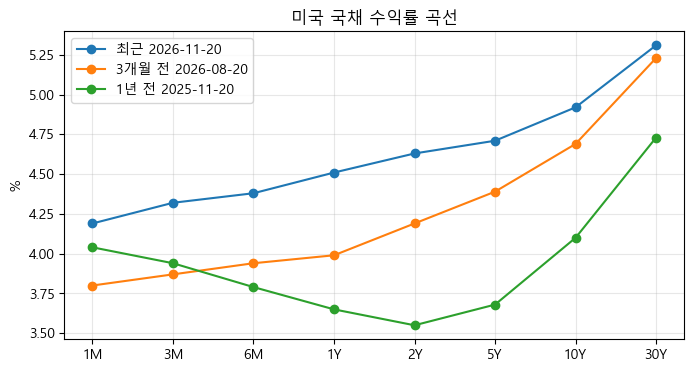

In [7]:
ax = curve.plot(marker="o", figsize=(8, 4), title="미국 국채 수익률 곡선")
ax.set_ylabel("%"); ax.grid(alpha=.3)

## 4. 환율과 달러지수

               원/달러    엔/달러  달러지수(광의)
date                                 
2026-11-20  1342.41  158.76     123.6


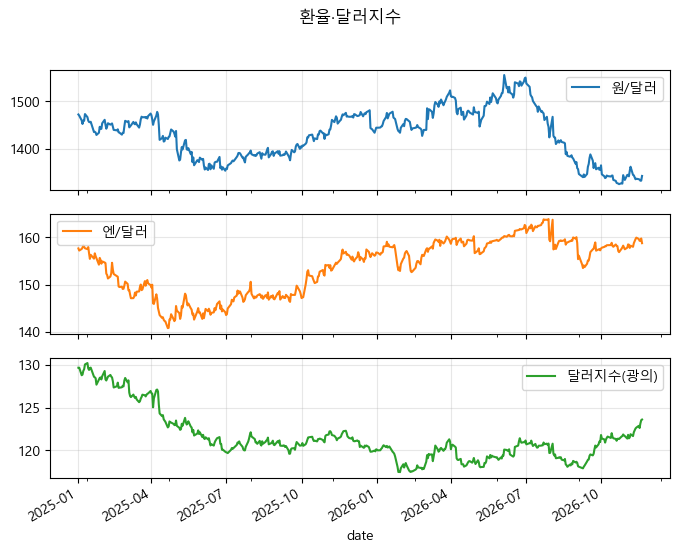

In [8]:
fx = fred(["DEXKOUS", "DEXJPUS", "DTWEXBGS"], START, ASOF).dropna(how="all")
fx.columns = ["원/달러", "엔/달러", "달러지수(광의)"]
print(fx.dropna().tail(1).round(2).to_string())
axes = fx.plot(subplots=True, figsize=(8, 6), title="환율·달러지수", legend=True)
for a in axes:
    a.grid(alpha=.3)

## 결과 읽는 법과 한계
- **미국 시리즈는 1~3 영업일 늦게** 들어옵니다(FRED 공표 일정). 국채 금리는 조회일 기준 직전 금요일까지일 수 있습니다.
- **한국·일본·영국 금리는 월평균**이라 지난달까지만 있습니다. 한은 기준금리 결정 당일 반영이 필요하면 한국은행 ECOS를 직접 써야 합니다.
- **국고채 만기별 곡선은 DeepSearch로 만들 수 없습니다**(채권 함수 미제공, 한국은행 시리즈 2024-04 중단). 근거: `research/data_gaps`.